# 04 — Model and Feature-Group Comparison

Compares feature groups **A**, **B**, and **C** on the same eligible observations,
the same split, and the same cross-validation folds.

- A: social media usage + demographic/context
- B: A + sleep variables
- C: B + stress and mental health indicators

Incremental changes (B−A, C−B) are interpreted relative to CV variability.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sm_project import config, data, features, modeling, viz

config.ensure_output_dirs()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
print("Project root:", ROOT)
print("Fixed seed:", config.SEED)

Project root: /Users/dhanudriya/Lecturer/ML-project-1
Fixed seed: 42


In [2]:
df = data.load_data()
analysis = data.eligible_sample(df)
train_idx, test_idx = features.make_split(analysis)
train_df = analysis.iloc[train_idx]
test_df = analysis.iloc[test_idx]
print("Analysis sample:", len(analysis), "| train:", len(train_df), "| test:", len(test_df))

# Reuse tuned parameters from notebook 03 when available.
tuned_path = config.TABLES_DIR / "03_tuned_params.json"
tuned_params = modeling.load_json(tuned_path) if tuned_path.exists() else {}
base_models = modeling.default_models()
models = {}
for name in ["Dummy (mean)", "Linear Regression", "Random Forest", "Hist Gradient Boosting"]:
    if name in tuned_params and name in base_models:
        estimator = base_models[name].set_params(**tuned_params[name])
    else:
        estimator = base_models[name]
    models[name] = estimator
print("Tuned parameters used:", tuned_params if tuned_params else "defaults (run notebook 03 first)")

Analysis sample: 4415 | train: 3532 | test: 883
Tuned parameters used: {'Random Forest': {'min_samples_leaf': 4, 'n_estimators': 600}, 'Hist Gradient Boosting': {'learning_rate': 0.03, 'max_leaf_nodes': 15}}


## 1. Run all feature-group and model combinations

In [3]:
from IPython.display import clear_output

cv = modeling.make_cv()
comparison_rows = []
prediction_rows = []
for group_name in ["A", "B", "C"]:
    feature_list = features.get_feature_group(group_name)
    for model_name, estimator in models.items():
        folds = modeling.evaluate_cv(
            train_df, feature_list, model_name, estimator, cv,
            scale_numeric=modeling.needs_scaling(model_name),
        )
        cv_summary = modeling.summarize_cv(folds)
        test_metrics, predictions, _ = modeling.fit_and_test(
            train_df, test_df, feature_list, model_name, estimator,
            scale_numeric=modeling.needs_scaling(model_name),
        )
        row = {
            "feature_group": group_name,
            "group_description": config.FEATURE_GROUP_DESCRIPTIONS[group_name],
            "model": model_name,
            "n_features": len(feature_list),
            "n_train": int(len(train_df)),
            "n_test": int(len(test_df)),
            **cv_summary,
            **{f"test_{k}": v for k, v in test_metrics.items()
               if k in {"mae", "rmse", "r2"}},
        }
        comparison_rows.append(row)
        prediction_rows.append(
            pd.DataFrame(
                {
                    "row_id": np.arange(len(test_df)),
                    "feature_group": group_name,
                    "model": model_name,
                    "y_true": test_df[config.TARGET].values,
                    "y_pred": predictions,
                }
            )
        )
        print(f"finished group {group_name} / {model_name}")

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))
comparison.to_csv(config.TABLES_DIR / "04_model_comparison.csv", index=False)
pd.concat(prediction_rows, ignore_index=True).to_csv(
    config.TABLES_DIR / "04_test_predictions.csv", index=False
)

finished group A / Dummy (mean)


finished group A / Linear Regression


finished group A / Random Forest


finished group A / Hist Gradient Boosting
finished group B / Dummy (mean)


finished group B / Linear Regression


...

finished group B / Hist Gradient Boosting
finished group C / Dummy (mean)


finished group C / Linear Regression


finished group C / Random Forest


finished group C / Hist Gradient Boosting


,feature_group,group_description,model,n_features,n_train,n_test,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std,cv_n_folds,test_mae,test_rmse,test_r2
0,A,Social media usage + demographic/context,Dummy (mean),9,3532,883,0.3090,0.0037,0.3886,0.0067,-0.0045,0.0063,5,0.3318,0.4094,-0.0012
1,A,Social media usage + demographic/context,Linear Regression,9,3532,883,0.2244,0.0047,0.2767,0.0046,0.4900,0.0249,5,0.2273,0.2809,0.5288
2,A,Social media usage + demographic/context,Random Forest,9,3532,883,0.2336,0.0049,0.2870,0.0043,0.4518,0.0222,5,0.2384,0.2940,0.4839
3,A,Social media usage + demographic/context,Hist Gradient Boosting,9,3532,883,0.2284,0.0067,0.2814,0.0069,0.4726,0.0321,5,0.2274,0.2819,0.5255
4,B,A + sleep variables,Dummy (mean),11,3532,883,0.3090,0.0037,0.3886,0.0067,-0.0045,0.0063,5,0.3318,0.4094,-0.0012
5,B,A + sleep variables,Linear Regression,11,3532,883,0.2204,0.0049,0.2722,0.0041,0.5066,0.0242,5,0.2234,0.2778,0.5391
6,B,A + sleep variables,Random Forest,11,3532,883,0.2258,0.0049,0.2778,0.0034,0.4863,0.0201,5,0.2293,0.2854,0.5135
7,B,A + sleep variables,Hist Gradient Boosting,11,3532,883,0.2246,0.0054,0.2776,0.0051,0.4869,0.0235,5,0.2265,0.2809,0.5287
8,C,B + stress and mental health indicators,Dummy (mean),13,3532,883,0.3090,0.0037,0.3886,0.0067,-0.0045,0.0063,5,0.3318,0.4094,-0.0012
9,C,B + stress and mental health indicators,Linear Regression,13,3532,883,0.2163,0.0035,0.2665,0.0028,0.5269,0.0204,5,0.2179,0.2692,0.5671


## 2. Incremental feature-group changes

In [4]:
metric_cols = ["cv_mae_mean", "cv_rmse_mean", "cv_r2_mean", "test_mae", "test_rmse", "test_r2"]
delta_rows = []
for model_name, sub in comparison.groupby("model"):
    sub = sub.set_index("feature_group")
    for previous, current in [("A", "B"), ("B", "C")]:
        row = {"model": model_name, "comparison": f"{current}-{previous}"}
        for column in metric_cols:
            row[column] = sub.loc[current, column] - sub.loc[previous, column]
        delta_rows.append(row)
deltas = pd.DataFrame(delta_rows)
display(deltas.round(4))
deltas.to_csv(config.TABLES_DIR / "04_feature_group_deltas.csv", index=False)

best_cv = comparison.sort_values("cv_mae_mean").groupby("feature_group").head(1)
print("Best model per feature group by training CV MAE:")
display(best_cv[["feature_group", "model", "cv_mae_mean", "cv_mae_std", "test_mae", "test_rmse", "test_r2"]].round(4))
best_cv.to_csv(config.TABLES_DIR / "04_best_per_group.csv", index=False)

,model,comparison,cv_mae_mean,cv_rmse_mean,cv_r2_mean,test_mae,test_rmse,test_r2
0,Dummy (mean),B-A,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,Dummy (mean),C-B,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,Hist Gradient Boosting,B-A,-0.0038,-0.0038,0.0143,-0.0010,-0.0010,0.0032
3,Hist Gradient Boosting,C-B,-0.0032,-0.0051,0.0187,-0.0028,-0.0053,0.0176
4,Linear Regression,B-A,-0.0040,-0.0045,0.0165,-0.0039,-0.0031,0.0103
5,Linear Regression,C-B,-0.0041,-0.0057,0.0204,-0.0055,-0.0086,0.0280
6,Random Forest,B-A,-0.0078,-0.0092,0.0345,-0.0091,-0.0086,0.0296
7,Random Forest,C-B,-0.0066,-0.0081,0.0296,-0.0068,-0.0108,0.0362


Best model per feature group by training CV MAE:


,feature_group,model,cv_mae_mean,cv_mae_std,test_mae,test_rmse,test_r2
9,C,Linear Regression,0.2163,0.0035,0.2179,0.2692,0.5671
5,B,Linear Regression,0.2204,0.0049,0.2234,0.2778,0.5391
1,A,Linear Regression,0.2244,0.0047,0.2273,0.2809,0.5288


## 3. Visual comparison

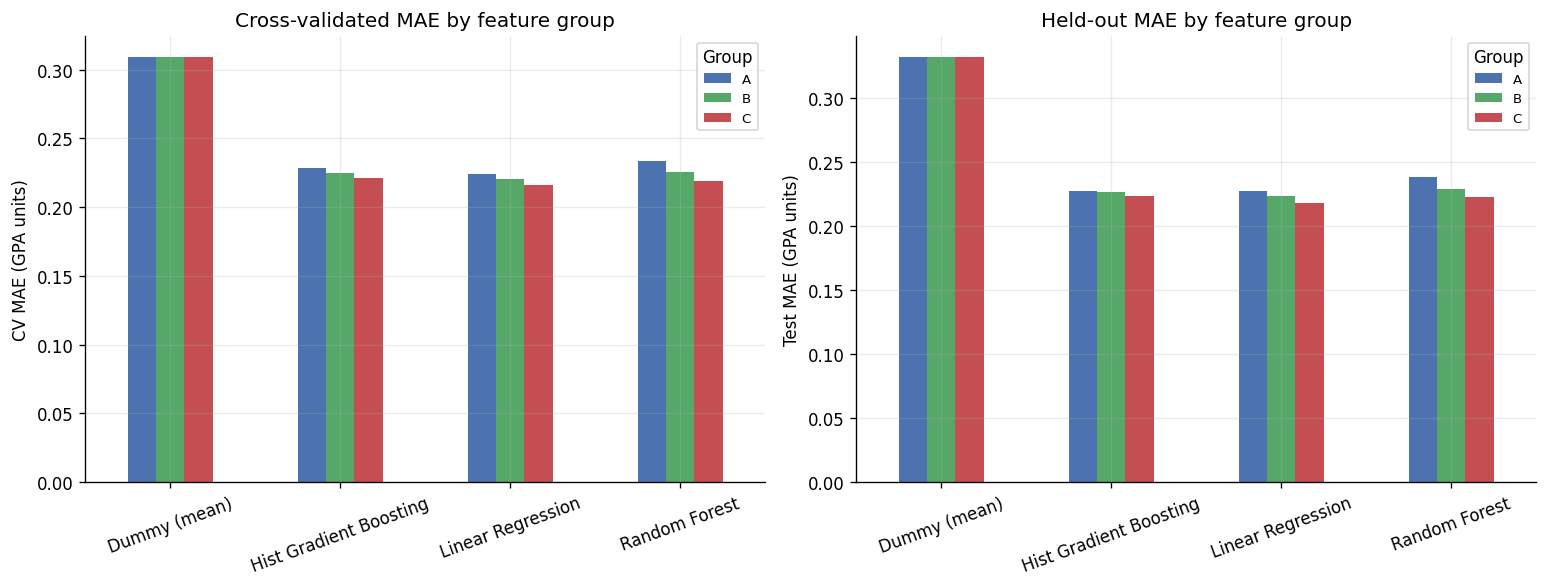

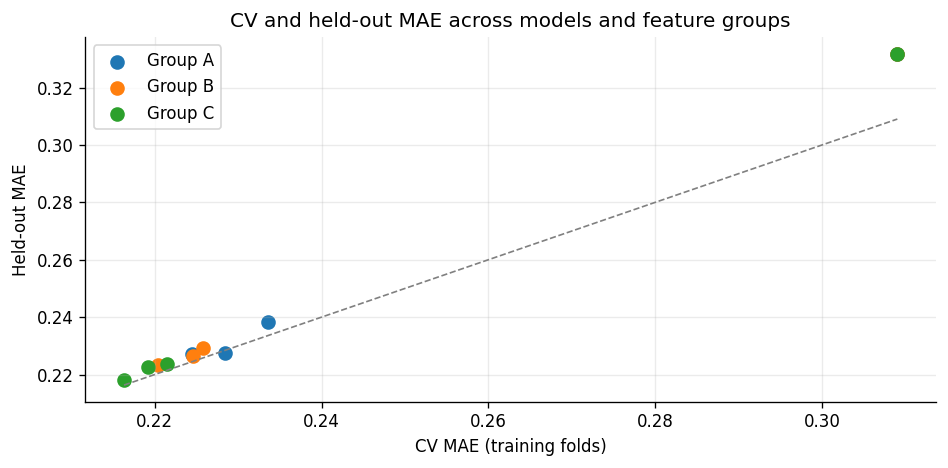

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/04_cv_vs_test_mae.png')

In [5]:
pivot_cv = comparison.pivot(index="model", columns="feature_group", values="cv_mae_mean")
pivot_test = comparison.pivot(index="model", columns="feature_group", values="test_mae")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pivot_cv.plot.bar(ax=axes[0], color=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_title("Cross-validated MAE by feature group")
axes[0].set_ylabel("CV MAE (GPA units)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(title="Group", fontsize=8)

pivot_test.plot.bar(ax=axes[1], color=["#4C72B0", "#55A868", "#C44E52"])
axes[1].set_title("Held-out MAE by feature group")
axes[1].set_ylabel("Test MAE (GPA units)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(title="Group", fontsize=8)
viz.finish_figure(fig, "04_feature_group_comparison.png")

fig, ax = plt.subplots(figsize=(8, 4))
for group_name in ["A", "B", "C"]:
    sub = comparison[comparison["feature_group"] == group_name]
    ax.scatter(sub["cv_mae_mean"], sub["test_mae"], label=f"Group {group_name}", s=60)
ax.plot([comparison["cv_mae_mean"].min(), comparison["cv_mae_mean"].max()],
        [comparison["cv_mae_mean"].min(), comparison["cv_mae_mean"].max()],
        "--", color="grey", linewidth=1)
ax.set_xlabel("CV MAE (training folds)")
ax.set_ylabel("Held-out MAE")
ax.set_title("CV and held-out MAE across models and feature groups")
ax.legend()
viz.finish_figure(fig, "04_cv_vs_test_mae.png")

## 4. Summary

In [6]:
best_row = comparison.sort_values("cv_mae_mean").iloc[0]
group_means = comparison.groupby("feature_group")[["cv_mae_mean", "test_mae"]].mean()
report_lines = [
    "# Feature-Group Comparison Summary",
    "",
    f"- Common eligible sample: n={len(analysis):,} (train {len(train_df):,}, test {len(test_df):,}); "
    "identical split and folds for all groups.",
    "- Group sizes: A=9 input features, B=11, C=13.",
    f"- Best configuration by training CV MAE: group {best_row['feature_group']} / {best_row['model']} "
    f"(CV MAE {best_row['cv_mae_mean']:.4f} +/- {best_row['cv_mae_std']:.4f}; "
    f"test MAE {best_row['test_mae']:.4f}, RMSE {best_row['test_rmse']:.4f}, R2 {best_row['test_r2']:.4f}).",
    "- Mean test MAE by group across models: "
    + "; ".join(f"{g}={v:.4f}" for g, v in group_means["test_mae"].items()) + ".",
    "- Mean CV MAE by group across models: "
    + "; ".join(f"{g}={v:.4f}" for g, v in group_means["cv_mae_mean"].items()) + ".",
    "",
    "## Interpretation",
    "",
    "- Adding sleep variables (B vs A) and stress/mental-health indicators (C vs B) is judged "
    "against fold-to-fold CV variability, not single decimal differences.",
    "- Because the predictors are strongly collinear, incremental groups may redistribute rather "
    "than add information; this is a predictive comparison, not causal mediation.",
    "- The test set was not used to choose any configuration. Test metrics are final descriptive "
    "evaluations of fixed pipelines.",
]
summary_text = "\n".join(report_lines)
(config.REPORTS_DIR / "04_model_comparison.md").write_text(summary_text, encoding="utf-8")
display(Markdown(summary_text))

# Feature-Group Comparison Summary

- Common eligible sample: n=4,415 (train 3,532, test 883); identical split and folds for all groups.
- Group sizes: A=9 input features, B=11, C=13.
- Best configuration by training CV MAE: group C / Linear Regression (CV MAE 0.2163 +/- 0.0035; test MAE 0.2179, RMSE 0.2692, R2 0.5671).
- Mean test MAE by group across models: A=0.2562; B=0.2527; C=0.2490.
- Mean CV MAE by group across models: A=0.2489; B=0.2450; C=0.2415.

## Interpretation

- Adding sleep variables (B vs A) and stress/mental-health indicators (C vs B) is judged against fold-to-fold CV variability, not single decimal differences.
- Because the predictors are strongly collinear, incremental groups may redistribute rather than add information; this is a predictive comparison, not causal mediation.
- The test set was not used to choose any configuration. Test metrics are final descriptive evaluations of fixed pipelines.